# Notebook 4: Korelasi Pearson dan Grad-CAM

Notebook ini punya dua bagian. Bagian pertama menghitung korelasi Pearson antara selisih statistik matriks (Δmean, ΔSD, Δcount) dan akurasi test CNN, lalu membandingkannya dengan hasil Rahadian et al. (2023). Bagian kedua memakai Grad-CAM pada model GADF untuk melihat bagian gambar (dan karena itu hari) mana yang membuat CNN menganggap sebuah segmen anomali.

Jalankan setelah Notebook 3.

## 1. Persiapan

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn as nn
import torch.nn.functional as F
from pathlib import Path

SEED, IMG = 42, 150
ROOT = Path('..')
PROC, FIG, RES, MODELS = ROOT/'data/processed', ROOT/'figures', ROOT/'results', ROOT/'models'

## 2. Korelasi Pearson

Tiap encoding (14 titik) punya tiga nilai Δ (dari Notebook 2) dan satu akurasi test (dari Notebook 3). Korelasi Pearson dihitung antara masing-masing Δ dan akurasi test. Angka paper: Δmean 0,705, ΔSD 0,944, Δcount 0,455.

In [2]:
delta = pd.read_csv(RES/'delta_per_encoding.csv')
acc = pd.read_csv(RES/'akurasi_encoding.csv')
df = delta.merge(acc[['encoding', 'test_acc']], on='encoding')
PAPER = {'delta_mean': 0.705, 'delta_sd': 0.944, 'delta_count': 0.455}
LABEL = {'delta_mean': 'Δmean', 'delta_sd': 'ΔSD', 'delta_count': 'Δcount'}

r_kita = {c: np.corrcoef(df[c], df.test_acc)[0, 1] for c in PAPER}
tab = pd.DataFrame({'fitur': [LABEL[c] for c in PAPER],
                    'r_kita': [round(r_kita[c], 3) for c in PAPER],
                    'r_paper': [PAPER[c] for c in PAPER]})
tab['peringkat_kita'] = tab.r_kita.rank(ascending=False).astype(int)
tab['peringkat_paper'] = tab.r_paper.rank(ascending=False).astype(int)
tab['selisih'] = (tab.r_kita - tab.r_paper).round(3)
tab.to_csv(RES/'korelasi_pearson.csv', index=False)
tab

,fitur,r_kita,r_paper,peringkat_kita,peringkat_paper,selisih
0,Δmean,0.496,0.705,2,2,-0.209
1,ΔSD,0.507,0.944,1,1,-0.437
2,Δcount,0.412,0.455,3,3,-0.043


Scatter berikut seperti Fig. 9 paper: tiap titik satu encoding, garis putus-putus adalah garis regresi linear. Warna menunjukkan keluarga encoding.

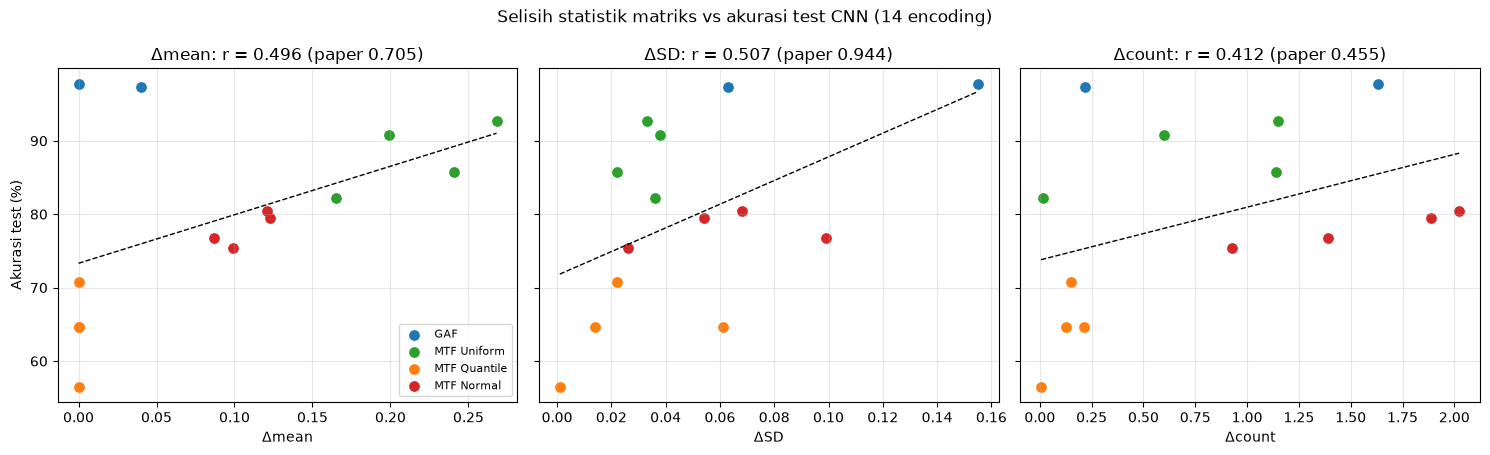

In [3]:
def family(n):
    return 'GAF' if n.startswith('GA') else ' '.join(n.split()[:2])
COL = {'GAF': 'tab:blue', 'MTF Uniform': 'tab:green', 'MTF Quantile': 'tab:orange', 'MTF Normal': 'tab:red'}
fam = df.encoding.map(family)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, c in zip(axes, PAPER):
    for f in COL:
        m = fam == f
        ax.scatter(df.loc[m, c], df.loc[m, 'test_acc'], color=COL[f], label=f, s=45)
    a, b = np.polyfit(df[c], df.test_acc, 1)
    xs = np.linspace(df[c].min(), df[c].max(), 50)
    ax.plot(xs, a * xs + b, 'k--', lw=1)
    ax.set_xlabel(LABEL[c]); ax.grid(alpha=0.3)
    ax.set_title(f'{LABEL[c]}: r = {r_kita[c]:.3f} (paper {PAPER[c]:.3f})')
axes[0].set_ylabel('Akurasi test (%)'); axes[0].legend(fontsize=8)
fig.suptitle('Selisih statistik matriks vs akurasi test CNN (14 encoding)')
fig.tight_layout(); fig.savefig(FIG/'12_korelasi_scatter.png', dpi=150); plt.show()

## 3. Grad-CAM pada model GADF

Grad-CAM menghitung bagian gambar mana yang paling mendorong keluaran CNN ke arah "anomali". Caranya: ambil peta fitur dari lapisan konvolusi terakhir, hitung seberapa besar tiap peta mempengaruhi keluaran (lewat gradien), jumlahkan peta-peta itu dengan bobot tersebut, lalu perbesar ke ukuran gambar.

Pada GADF, piksel (i, j) mewakili hubungan antara hari ke-i dan hari ke-j. Peta panas 150 x 150 piksel dikembalikan ke matriks 20 x 20 (rata-rata per sel, dengan memperhitungkan urutan baris `origin='lower'`), lalu skor tiap hari adalah jumlah nilai pada baris dan kolom hari itu, dinormalisasi ke 0 sampai 1.

In [4]:
def block(i, o):
    return [nn.Conv2d(i, o, 3), nn.ReLU(), nn.MaxPool2d(2)]

def make_model():
    return nn.Sequential(*block(3, 16), *block(16, 32), *block(32, 64),
                         nn.Flatten(), nn.Linear(64 * 17 * 17, 512), nn.ReLU(), nn.Linear(512, 1))

model = make_model()
model.load_state_dict(torch.load(MODELS/'GADF.pt'))
model.eval()

cmap = plt.get_cmap('rainbow')
pix = (np.arange(IMG) * 20) // IMG
def to_image(mats_, vmin, vmax):
    scaled = np.clip((mats_ - vmin) / (vmax - vmin), 0, 1)
    rgb = (cmap(scaled)[..., :3] * 255).astype(np.uint8)[:, ::-1]
    return rgb[:, pix][:, :, pix]

def gradcam(x):
    A = model[:8](x).detach().requires_grad_(True)           # peta fitur konvolusi terakhir (64 x 34 x 34)
    logit = model[8:](A)[0, 0]
    g, = torch.autograd.grad(logit, A)
    cam = F.relu((g.mean(dim=(2, 3), keepdim=True) * A).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(IMG, IMG), mode='bilinear', align_corners=False)[0, 0].detach().numpy()
    return cam / cam.max() if cam.max() > 0 else cam, torch.sigmoid(logit).item()

def cam_to_days(cam):
    H = np.zeros((20, 20))
    for i in range(20):
        for j in range(20):
            H[i, j] = cam[np.ix_(np.where(19 - pix == i)[0], np.where(pix == j)[0])].mean()
    s = H.sum(axis=1) + H.sum(axis=0)
    return H, (s / s.max() if s.max() > 0 else s)

### Memilih contoh

Contoh dipilih dari segmen anomali di data test, memakai seed tetap: dua segmen yang diklasifikasi benar (dari dua game berbeda) dan satu segmen yang salah diklasifikasi (anomali yang diprediksi normal), jika ada.

In [5]:
d = np.load(PROC/'segmen.npz')
meta = pd.read_csv(PROC/'segmen_meta.csv')
mats = np.load(PROC/'matriks_encoding.npz')
N = len(meta)
mask, normal_z, anomali_z = d['mask_anomali'], d['normal_z'], d['anomali_z']
GN = {'dark_souls_3': 'Dark Souls 3', 'ets2': 'Euro Truck Simulator 2', 'garrys_mod': "Garry's Mod",
      'rainbow_six_siege': 'Rainbow Six Siege', 'stardew_valley': 'Stardew Valley', 'terraria': 'Terraria'}

pt = pd.read_csv(RES/'prediksi_test.csv')
an = pt[pt.kelas == 1].copy()
an['game'] = [meta.game[s] for s in an.segmen_id]
rng = np.random.default_rng(SEED)

ok = an[an.GADF > 0.5].sample(frac=1, random_state=SEED)
picked, used = [], set()
for _, r in ok.iterrows():
    if r.game not in used:
        picked.append(('Benar', int(r.gambar_id))); used.add(r.game)
    if len(picked) == 2:
        break
bad = an[an.GADF <= 0.5]
if len(bad):
    picked.append(('Salah', int(bad.sample(1, random_state=SEED).gambar_id.iloc[0])))
print('Anomali di test:', len(an), '| benar:', len(ok), '| salah:', len(bad))
print([(k, int(g)) for k, g in picked])

Anomali di test: 185 | benar: 182 | salah: 3
[('Benar', 1380), ('Benar', 1529), ('Salah', 1630)]


Hasil Grad-CAM untuk tiap contoh. Kolom: gambar GADF, overlay Grad-CAM (gambar dijadikan abu-abu supaya peta panas terlihat), deret waktu segmen (lingkaran merah menandai hari yang disuntik), dan skor kepentingan per hari (batang merah adalah hari yang disuntik).

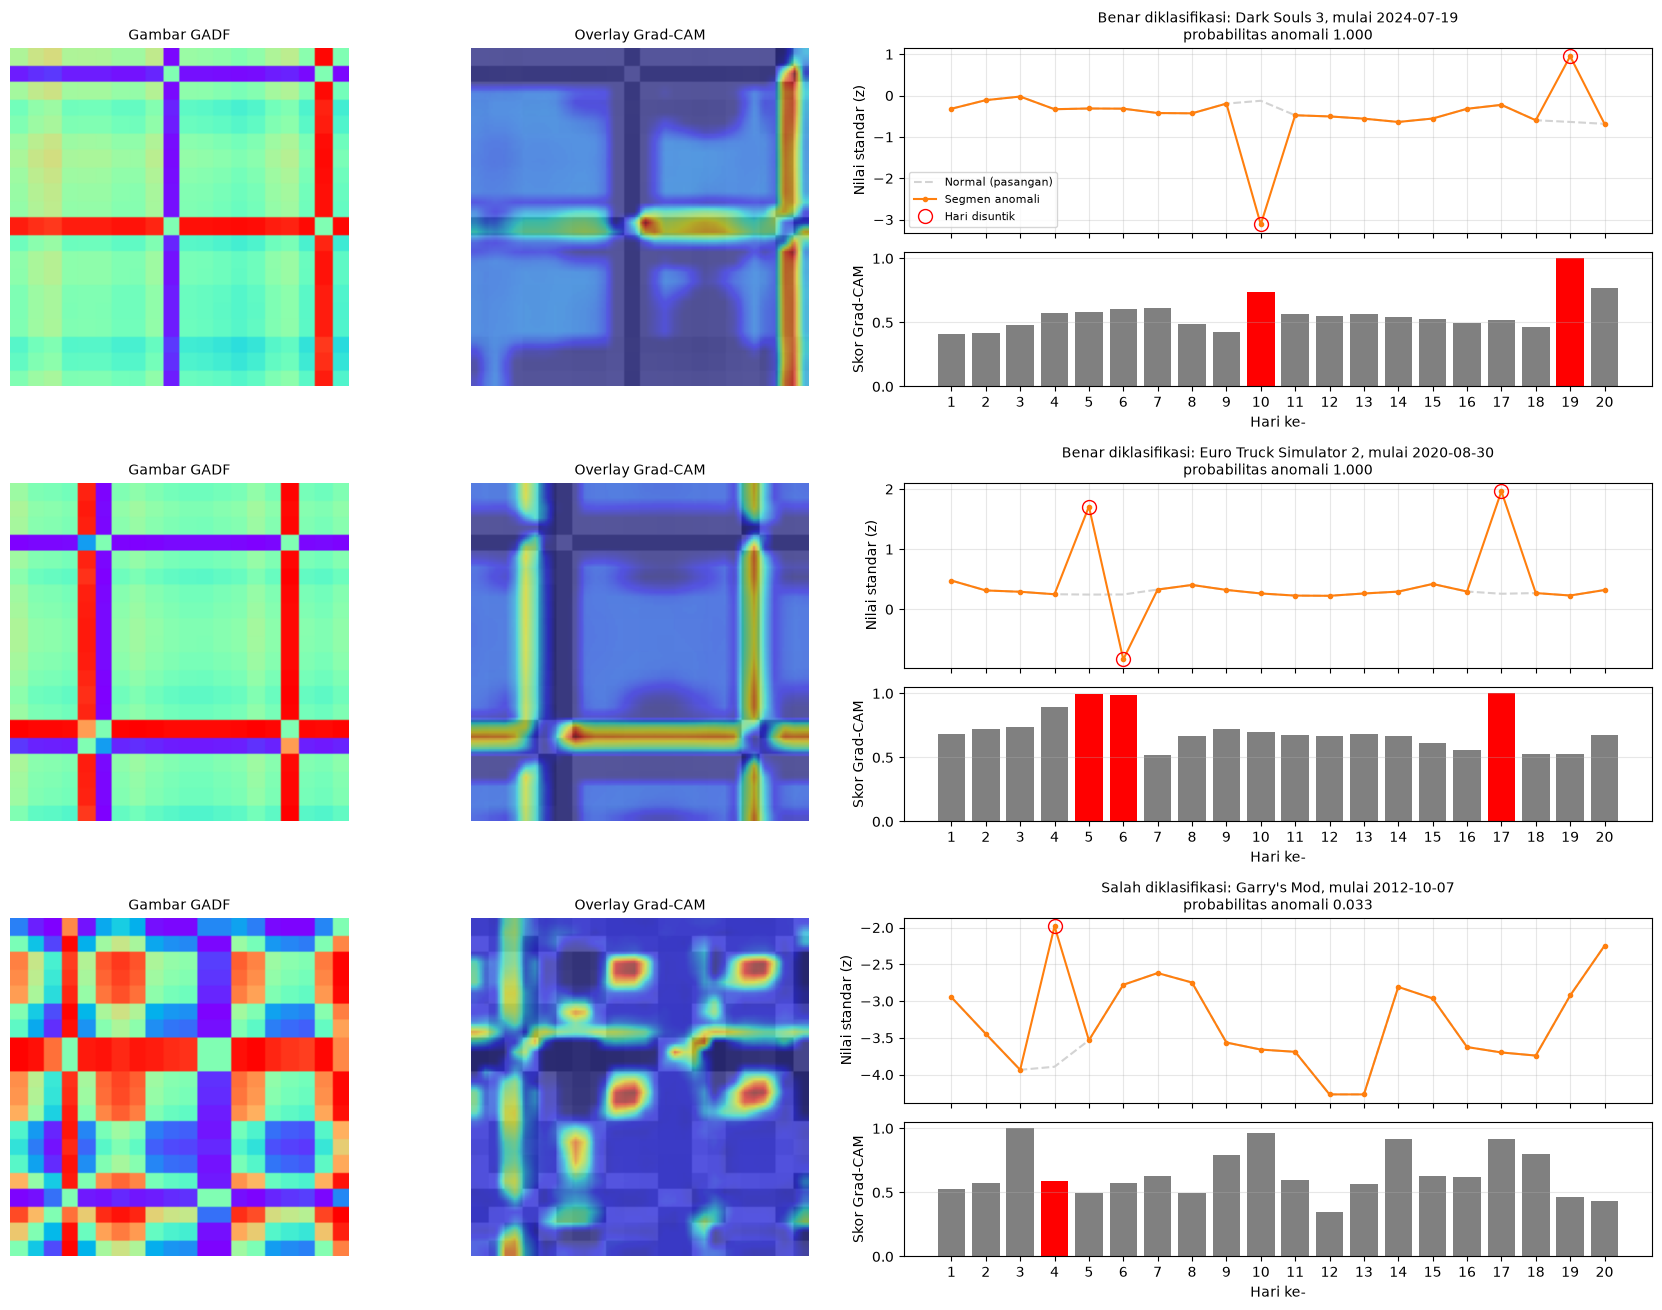

,jenis,gambar_id,segmen_id,game,tanggal_mulai,prob_anomali,hari_disuntik,hari_teratas_gradcam
0,Benar,1380,151,dark_souls_3,2024-07-19,1.000,"[10, 19]","[19, 20]"
1,Benar,1529,300,ets2,2020-08-30,1.000,"[5, 6, 17]","[5, 6, 17]"
2,Salah,1630,401,garrys_mod,2012-10-07,0.033,[4],[3]


In [6]:
gray = lambda im: np.repeat(im.mean(axis=2, keepdims=True), 3, axis=2).astype(np.uint8)
x = np.arange(1, 21)
rows_info = []
fig = plt.figure(figsize=(17, 4.4 * len(picked)))
gs = fig.add_gridspec(len(picked), 3, width_ratios=[1, 1, 1.9])
for r, (kind, gid) in enumerate(picked):
    sid = gid - N
    im = to_image(mats['GADF'][[gid]], -1, 1)[0]
    xt = torch.from_numpy(im).permute(2, 0, 1)[None].float() / 255
    cam, prob = gradcam(xt)
    H, s = cam_to_days(cam)
    inj = np.where(mask[sid])[0]
    top = np.argsort(-s)[:len(inj)]
    title = f"{kind} diklasifikasi: {GN[meta.game[sid]]}, mulai {meta.tanggal_mulai[sid]}\nprobabilitas anomali {prob:.3f}"
    ax = fig.add_subplot(gs[r, 0]); ax.imshow(im); ax.axis('off'); ax.set_title('Gambar GADF', fontsize=10)
    ax = fig.add_subplot(gs[r, 1]); ax.imshow(gray(im)); ax.imshow(cam, cmap='jet', alpha=0.55, vmin=0, vmax=1); ax.axis('off')
    ax.set_title('Overlay Grad-CAM', fontsize=10)
    sub = gs[r, 2].subgridspec(2, 1, height_ratios=[1.1, 0.8], hspace=0.12)
    a1 = fig.add_subplot(sub[0]); a2 = fig.add_subplot(sub[1], sharex=a1)
    a1.plot(x, normal_z[sid], color='lightgray', ls='--', label='Normal (pasangan)')
    a1.plot(x, anomali_z[sid], 'o-', ms=3, color='tab:orange', label='Segmen anomali')
    a1.plot(x[inj], anomali_z[sid][inj], 'o', color='red', ms=10, mfc='none', label='Hari disuntik')
    a1.set_ylabel('Nilai standar (z)'); a1.grid(alpha=0.3); a1.set_title(title, fontsize=10); plt.setp(a1.get_xticklabels(), visible=False)
    if r == 0: a1.legend(fontsize=8)
    a2.bar(x, s, color=['red' if i in inj else 'gray' for i in range(20)])
    a2.set_xticks(x); a2.set_xlabel('Hari ke-'); a2.set_ylabel('Skor Grad-CAM'); a2.grid(alpha=0.3, axis='y')
    rows_info.append(dict(jenis=kind, gambar_id=gid, segmen_id=sid, game=meta.game[sid], tanggal_mulai=meta.tanggal_mulai[sid],
                          prob_anomali=round(prob, 3), hari_disuntik=[int(v) for v in inj + 1], hari_teratas_gradcam=sorted(int(v) for v in top + 1)))
fig.tight_layout(); fig.savefig(FIG/'13_gradcam_contoh.png', dpi=150); plt.show()
info = pd.DataFrame(rows_info)
info.to_csv(RES/'gradcam_contoh.csv', index=False)
info

## 4. Pembahasan

**Korelasi Pearson.** Urutan pengaruh kita sama dengan paper (ΔSD, lalu Δmean, lalu Δcount), tetapi hanya secara nominal. Nilai ΔSD (0,507) dan Δmean (0,496) hampir sama, dan dengan hanya 14 titik selisih sekecil itu tidak bisa ditafsirkan. Perbedaan yang jelas ada pada kekuatannya: ΔSD turun jauh dari 0,944 di paper menjadi 0,507. Beberapa kemungkinan penyebabnya, berdasarkan temuan Tahap 2 dan 3:

1. **MTF Uniform kuat tanpa ΔSD yang besar.** Di paper, MTF Uniform punya ΔSD sekitar 0,14 sampai 0,16, sehingga ΔSD menjelaskan akurasinya yang tinggi. Di data kita ΔSD MTF Uniform hanya 0,02 sampai 0,04, tetapi akurasinya 82 sampai 93%. Kekuatannya datang dari Δmean yang besar (0,17 sampai 0,27), bukan dari ΔSD. Titik hijau di scatter ΔSD karena itu berada jauh di atas garis regresi.
2. **Pola "kelompok" di paper tidak muncul.** Di paper, korelasi yang sangat tinggi banyak ditentukan oleh MTF Normal yang semua nilai Δ-nya nol dan akurasinya 50%. Di data kita MTF Normal tidak merah semua, sehingga titik-titik itu pindah ke tengah (akurasi 75 sampai 81%) dan hubungan yang rapi hilang.
3. **Δmean tidak bisa membedakan encoding terbaik dari terburuk.** GADF selalu punya Δmean 0 (matriksnya antisimetris) dan MTF Quantile juga 0 (isi bin selalu sama banyak). Jadi pada Δmean = 0 ada encoding dengan akurasi tertinggi (GADF, 97,8%) sekaligus terendah (MTF Quantile 10, 56,5%). Selain itu, Δmean GASF hanya 0,04, jauh dari 0,797 di paper. Dugaan kami: anomali pada data kita naik dan turun secara acak sehingga efeknya pada rata-rata matriks saling meniadakan, sedangkan anomali over-voltage di paper selalu satu arah. Dugaan ini belum diuji.
4. **Δcount hampir konstan di GAF.** Jumlah pemain harian hampir tidak pernah sama dua hari berturut-turut, sehingga jumlah nilai unik pada GADF dan GASF selalu mendekati batas maksimumnya baik pada segmen normal maupun anomali. Δcount jadi tidak banyak membedakan, dan ia tetap yang terlemah seperti di paper (0,412 versus 0,455). Itu satu-satunya korelasi yang mendekati paper.
5. **Jumlah titik kecil dan akurasi bergoyang.** Korelasi dari 14 titik sangat dipengaruhi pengelompokan per keluarga encoding, dan akurasi test berasal dari 370 gambar dalam satu kali training (galat sekitar 2 sampai 3 poin).

Kesimpulannya, selisih statistik matriks masih memberi petunjuk kasar (encoding dengan semua Δ kecil, seperti MTF Quantile, memang cenderung buruk), tetapi pada data jumlah pemain Steam ini ia tidak bisa menggantikan percobaan CNN seyakin pada data tegangan di paper.

**Grad-CAM.** Pada dua contoh yang benar, Grad-CAM menyorot garis-garis pada gambar GADF yang memang muncul di hari yang disuntik (satu hari anomali membuat satu baris dan satu kolom berubah di seluruh gambar). Pada contoh Euro Truck Simulator 2, tiga hari dengan skor tertinggi sama dengan tiga hari yang disuntik. Pada contoh Dark Souls 3, dua skor tertinggi adalah hari 19 (disuntik) dan hari 20 (bertetangga dengannya), dan hari 10 yang disuntik berada di urutan ketiga, kemungkinan karena peta Grad-CAM beresolusi rendah sehingga hari bertetangga ikut terang. Pada contoh yang salah (Garry's Mod, 2012), perhatian CNN tersebar ke beberapa hari dan hari yang disuntik hanya memperoleh skor menengah. Segmen itu sudah naik turun cukup besar secara alami, sehingga lonjakan buatan tidak menonjol. Tiga contoh ini bersifat ilustrasi dan bukan ukuran ketepatan.